## Using LSTM to analyze resting state networks

This notebook includes code to classify ADHD from healthy controls using LSTM model with rs-fMRI data.

First let's import the relevant libraries

In [18]:
from nilearn import datasets
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
import warnings

warnings.filterwarnings("ignore")
plt.style.use("ggplot")

# nilearn - neuroimaging tailored library
from nilearn.maskers import NiftiMapsMasker
from nilearn import plotting

# sklearn - basic ML tools
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve
from sklearn import metrics

# keras - for NN models
from keras.models import Model, Sequential
from keras.layers import Input, Dense
from keras.layers import LSTM
from keras import optimizers
from keras.utils import plot_model
from keras import utils
from sklearn.metrics import roc_curve


# scipy- statistical analysis tools
from scipy.stats import ttest_1samp
# from scipy import interp

## Preparing data for analysis ##

Import data, and exctract features

In [19]:
## load the smith (ICA based) mask
## 'rsn10': 10 ICA maps from the above that matched across task and rest
# http://brainmap.org/pubs/SmithPNAS09.pdf

smith_atlas = datasets.fetch_atlas_smith_2009()
smith_atlas_rs_networks = smith_atlas.maps

[fetch_atlas_smith_2009] Dataset directory found: /home/pawlowiczf/nilearn_data/smith_2009


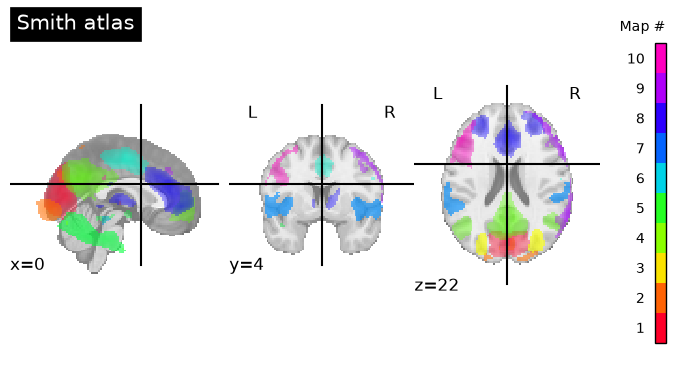

In [20]:
plotting.plot_prob_atlas(smith_atlas_rs_networks, title="Smith atlas", colorbar=True)
plotting.show()

In [21]:
# Import preprocessed, ready-to-go, datasets
adhd_data = datasets.fetch_adhd(n_subjects=10)

[fetch_adhd] Dataset directory found: /home/pawlowiczf/nilearn_data/adhd


In [22]:
# exploring the header of one image
import nibabel as nib

img = nib.load(adhd_data["func"][0])

print(img.header["dim"])
print(img.header["pixdim"])

[  4  61  73  61 176   1   1   1]
[-1.  3.  3.  3.  2.  0.  0.  0.]


In [23]:
# Region signals extraction- exctract the values of the ten networks

masker = NiftiMapsMasker(
    maps_img=smith_atlas_rs_networks,  # Smith stals
    standardize=True,  # centers and norms the time-series
    memory="nilearn_cache",  # cache
    verbose=0,
)  # do not print verbose

In [24]:
all_subjects_data = []
labels = []  # 1 if ADHD, 0 if control

for func_file, confound_file, adhd_label in zip(
    adhd_data.func, adhd_data.confounds, adhd_data.phenotypic["adhd"]
):
    time_series = masker.fit_transform(func_file, confounds=confound_file)

    all_subjects_data.append(time_series)
    labels.append(int(adhd_label))

In [25]:
print("N control:", labels.count(0))
print("N adhd:", labels.count(1))

N control: 3
N adhd: 7


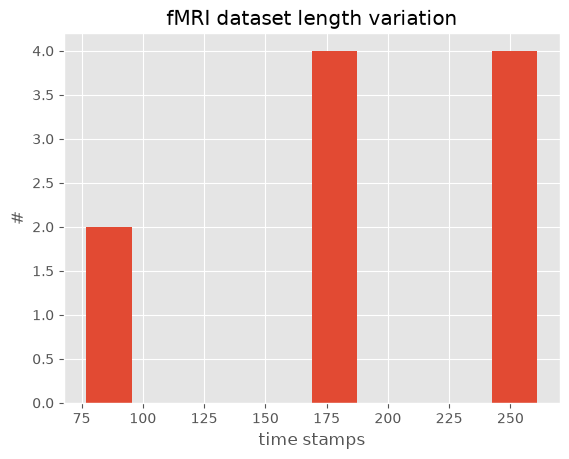

In [26]:
plt.hist([len(i) for i in all_subjects_data])
plt.title("fMRI dataset length variation")
plt.xlabel("time stamps")
plt.ylabel("#")
plt.show()

In [27]:
# find the longest image
max_len_image = np.max([len(i) for i in all_subjects_data])

In [28]:
# reshape

all_subjects_data_reshaped = []
for subject_data in all_subjects_data:
    # Padding
    N = max_len_image - len(subject_data)
    padded_array = np.pad(
        subject_data, ((0, N), (0, 0)), "constant", constant_values=(0)
    )
    subject_data = padded_array
    subject_data = np.array(subject_data)
    subject_data.reshape(subject_data.shape[0], subject_data.shape[1], 1)
    all_subjects_data_reshaped.append(subject_data)

In [29]:
# shape of data

# 40 subjects
# 261 time stamps
# 10 netwroks values

np.array(all_subjects_data_reshaped).shape

(10, 261, 10)

In [30]:
# The data, split between train and test sets.


def get_train_test(X, y, i, verbrose=False):
    """
    split to train and test and reshape data
    X data
    y labels
    i random state
    """
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=i
    )

    # Reshapes data to 4D for Hierarchical RNN.
    t_shape = np.array(all_subjects_data_reshaped).shape[1]
    RSN_shape = np.array(all_subjects_data_reshaped).shape[2]

    X_train = np.reshape(X_train, (len(X_train), t_shape, RSN_shape))
    X_test = np.reshape(X_test, (len(X_test), t_shape, RSN_shape))

    X_train = X_train.astype("float32")
    X_test = X_test.astype("float32")

    if verbrose:
        print(X_train.shape[0], "train samples")
        print(X_test.shape[0], "test samples")

    # Converts class vectors to binary class matrices.
    y_train = utils.to_categorical(y_train, 2)
    y_test = utils.to_categorical(y_test, 2)

    return X_train, X_test, y_train, y_test

## Build the LSTM model

In [31]:
# create the model

model = Sequential()

# LSTM layers -
# Long Short-Term Memory layer - Hochreiter 1997.
t_shape = np.array(all_subjects_data_reshaped).shape[1]
RSN_shape = np.array(all_subjects_data_reshaped).shape[2]

model.add(
    LSTM(
        units=70,  # dimensionality of the output space
        dropout=0.4,  # Fraction of the units to drop (inputs)
        recurrent_dropout=0.15,  # Fraction of the units to drop (recurent state)
        return_sequences=True,  # return the last state in addition to the output
        input_shape=(t_shape, RSN_shape),
    )
)

model.add(LSTM(units=60, dropout=0.4, recurrent_dropout=0.15, return_sequences=True))

model.add(LSTM(units=50, dropout=0.4, recurrent_dropout=0.15, return_sequences=True))

model.add(LSTM(units=40, dropout=0.4, recurrent_dropout=0.15, return_sequences=False))


model.add(Dense(units=2, activation="sigmoid"))

model.compile(
    loss="binary_crossentropy",
    optimizer=optimizers.Adam(learning_rate=0.001),
    metrics=["binary_accuracy"],
)

print(model.summary())

E0000 00:00:1793779490.186966  108327 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 261, 70)        │        22,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 261, 60)        │        31,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 261, 50)        │        22,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 40)             │        14,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │            82 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 90,962 (355.32 KB)

 Trainable params: 90,962 (355.32 KB)

 Non-trainable params: 0 (0.00 B)

None


In [32]:
plot_model(model, show_shapes=True, show_layer_names=True)

You must install pydot (`pip install pydot`) for `plot_model` to work.


## Train the LSTM model

8 train samples
2 test samples
Epoch 1/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 29s 29s/step - binary_accuracy: 0.3333 - loss: 0.7015 - val_binary_accuracy: 1.0000 - val_loss: 0.6918
Epoch 2/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - binary_accuracy: 0.7500 - loss: 0.6889 - val_binary_accuracy: 1.0000 - val_loss: 0.6914
Epoch 3/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - binary_accuracy: 0.7500 - loss: 0.6915 - val_binary_accuracy: 1.0000 - val_loss: 0.6913
Epoch 4/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - binary_accuracy: 0.6667 - loss: 0.6899 - val_binary_accuracy: 1.0000 - val_loss: 0.6907
Epoch 5/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step - binary_accuracy: 0.5833 - loss: 0.6916 - val_binary_accuracy: 1.0000 - val_loss: 0.6900
Epoch 6/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - binary_accuracy: 0.5000 - loss: 0.6928 - val_binary_accuracy: 1.0000 - val_loss: 0.6896
Epoch 7/30
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - binary_accuracy: 0.6667 - loss: 0.6767 - val_binary_accuracy: 1.0000 - val_loss: 0.6881
Epoch 8/

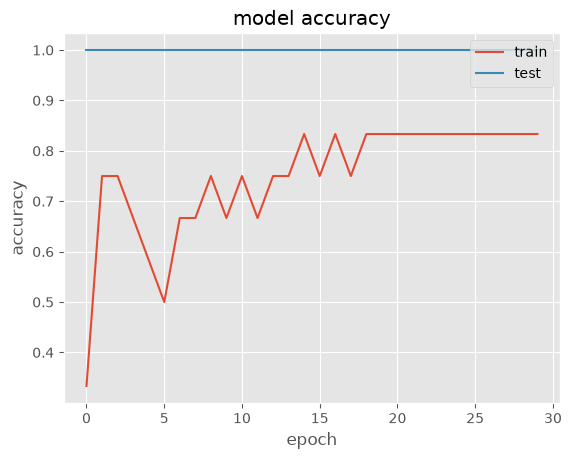

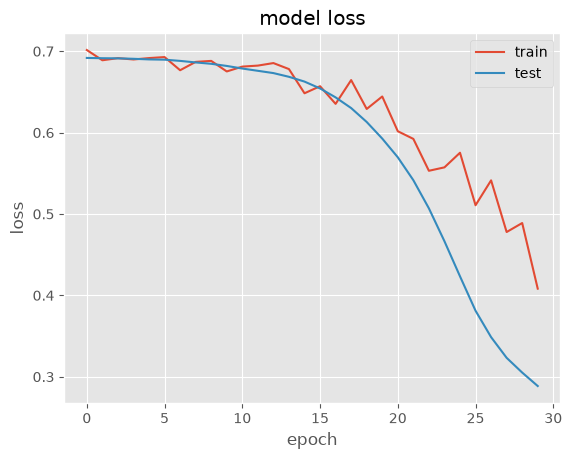

In [33]:
X_train, X_test, y_train, y_test = get_train_test(
    all_subjects_data_reshaped, labels, i=8, verbrose=True
)

history = model.fit(X_train, y_train, validation_split=0.2, epochs=30)

# summarize history for accuracy
plt.plot(history.history["binary_accuracy"])
plt.plot(history.history["val_binary_accuracy"])
plt.title("model accuracy")
plt.ylabel("accuracy")
plt.xlabel("epoch")
plt.legend(["train", "test"], loc="upper right")
plt.show()

# summarize history for loss
plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])
plt.title("model loss")
plt.ylabel("loss")
plt.xlabel("epoch")
plt.legend(["train", "test"], loc="upper right")
plt.show()

## Evaluate the LSTM model

In [34]:
from sklearn.metrics import accuracy_score


def boostrapping_hypothesis_testing(
    X_train, y_train, X_test, y_test, n_iterations=5, n_epochs=50
):
    """
    hypothesis testing function
    X_train, y_train, X_test, y_test- the data
    n_iterations- number of bootdtaping iterations
    n_epochs - number of epochs for model's training
    """

    accuracy = []  ## model accuracy
    roc_msrmnts_fpr = []  ## false positive rate
    roc_msrmnts_tpr = []  ## true positive rate

    # run bootstrap
    for i in range(n_iterations):
        # prepare train and test sets
        X_train, X_test, y_train, y_test = get_train_test(
            all_subjects_data_reshaped, labels, i=i, verbrose=False
        )
        # fit model
        print("fitting..")
        model.fit(X_train, y_train, validation_split=0.2, epochs=n_epochs)

        # evaluate model
        print("evaluating..")
        y_pred = model.predict(X_test)
        y_test_1d = [i[0] for i in y_test]
        y_pred_1d = [1.0 if i[0] > 0.5 else 0.0 for i in y_pred]

        fpr, tpr, _ = roc_curve(y_test_1d, y_pred_1d)

        acc_score = accuracy_score(y_test_1d, y_pred_1d)

        accuracy.append(acc_score)
        roc_msrmnts_fpr.append(fpr)
        roc_msrmnts_tpr.append(tpr)

    return accuracy, roc_msrmnts_fpr, roc_msrmnts_tpr


accuracy, roc_msrmnts_fpr, roc_msrmnts_tpr = boostrapping_hypothesis_testing(
    X_train, y_train, X_test, y_test
)

fitting..
Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - binary_accuracy: 0.8333 - loss: 0.5267 - val_binary_accuracy: 0.5000 - val_loss: 0.8548
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - binary_accuracy: 0.8333 - loss: 0.5106 - val_binary_accuracy: 0.5000 - val_loss: 0.8765
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step - binary_accuracy: 0.8333 - loss: 0.5070 - val_binary_accuracy: 0.5000 - val_loss: 0.9019
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - binary_accuracy: 0.8333 - loss: 0.4783 - val_binary_accuracy: 0.5000 - val_loss: 0.9302
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - binary_accuracy: 0.8333 - loss: 0.5084 - val_binary_accuracy: 0.5000 - val_loss: 0.9617
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - binary_accuracy: 0.8333 - loss: 0.4832 - val_binary_accuracy: 0.5000 - val_loss: 0.9950
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - binary_accuracy: 0.8333 - loss: 0.4059 - val_binary_accuracy: 0.5000 - val_loss: 1.0312
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━

In [35]:
# def calc_p_val(stats, h0, n_iterations):
def calc_p_val(stats, h0):
    """
    finds the p value for the results

    """
    # calc pval
    tset, pval = ttest_1samp(stats, h0)

    return pval


p_val = calc_p_val(accuracy, 0.5)

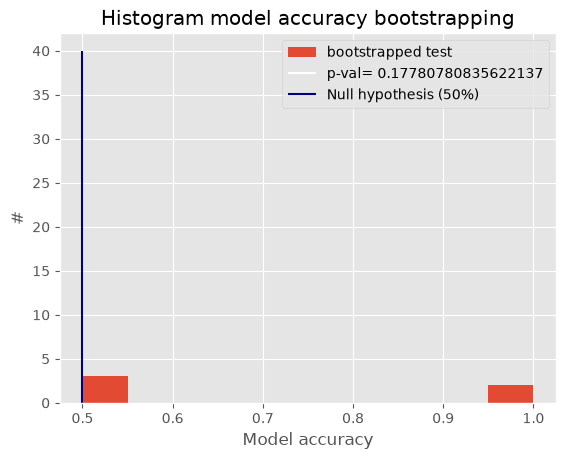

In [36]:
def plot_p_value(stats, p_val):
    """
    plots the bootstrapping results with the null hypothesis value
    """

    plt.hist(stats, label="bootstrapped test")
    plt.vlines(0.5, 0, 40, color="white", label="p-val= {}".format(p_val))
    plt.vlines(0.5, 0, 40, color="navy", label="Null hypothesis (50%)")

    plt.title("Histogram model accuracy bootstrapping")
    plt.xlabel("Model accuracy")
    plt.ylabel("#")
    plt.legend()
    plt.plot()


plot_p_value(accuracy, p_val)

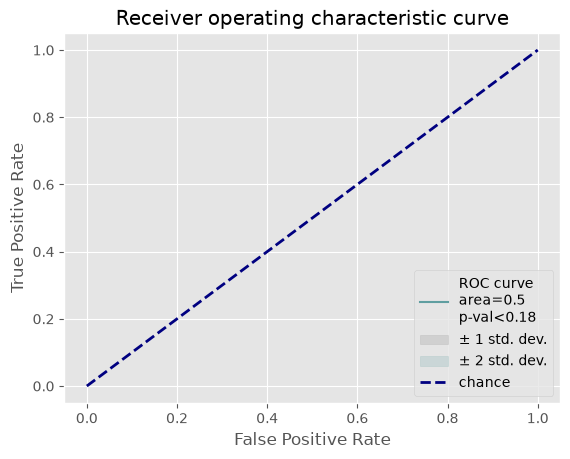

In [37]:
def plot_roc_curve(fpr_vals, tpr_vals, roc_auc, p_val):
    """
    This function plots the median value of the roc for the boostrapped
      results calculated above.

    fpr stand for false-positive rate
    tpr stands for true-positive rate
    roc_auc is the area under curve
    """

    ## get the values
    N = len(fpr_vals)
    tprs = []
    median_fpr = np.linspace(0, 1, 100)
    #  tprs=[interp(median_fpr, fpr_vals[i], tpr_vals[i]) for i in range(N)]
    tprs = [np.interp(median_fpr, fpr_vals[i], tpr_vals[i]) for i in range(N)]
    std_tpr = np.std(tprs, axis=0)

    mean_tpr = np.mean(tprs, axis=0)
    median_tpr = np.median(tprs, axis=0)
    median_tpr[-1] = 1.0

    tprs_upper_2 = np.minimum(mean_tpr + 2 * std_tpr, 1)
    tprs_lower_2 = np.maximum(mean_tpr - 2 * std_tpr, 0)

    tprs_upper_1 = np.minimum(mean_tpr + std_tpr, 1)
    tprs_lower_1 = np.maximum(mean_tpr - std_tpr, 0)

    median_auc_roc = np.median(roc_auc)

    ## plot
    if p_val < 0.05:
        p_val = 0.05
    plt.plot(
        median_fpr,
        median_tpr,
        color="cadetblue",
        label="ROC curve \narea={} \np-val<{}".format(
            np.round(median_auc_roc, 2), np.round(p_val, 2)
        ),
    )
    plt.fill_between(
        median_fpr,
        tprs_lower_2,
        tprs_upper_2,
        color="grey",
        alpha=0.2,
        label=r"$\pm$ 1 std. dev.",
    )

    plt.fill_between(
        median_fpr,
        tprs_lower_1,
        tprs_upper_1,
        color="cadetblue",
        alpha=0.2,
        label=r"$\pm$ 2 std. dev.",
    )

    plt.plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--", label=r"chance")

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("Receiver operating characteristic curve")
    plt.legend(loc="lower right")

    plt.show()


plot_roc_curve(roc_msrmnts_fpr, roc_msrmnts_tpr, accuracy, p_val)